# 02 — Curvas de treino e validação
Os resultados registrados vieram da CNN de três blocos convolucionais com 16, 32 e 64 filtros, treinada em CPU com a configuração `configs/baseline_cpu.yaml`. Para repetir a rodada, execute na raiz do projeto `python scripts/train.py --config configs/baseline_cpu.yaml`.

A acurácia de treino por época agrega previsões com aumento de dados e pesos que mudam ao longo da época. O notebook 03 compara os dois conjuntos em modo de inferência com o mesmo checkpoint.

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

# O comando de execução também funciona a partir da pasta notebooks/.
import os
os.chdir(ROOT)

import json
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

reports = ROOT / 'reports'
metadata = json.loads((reports / 'run_metadata.json').read_text(encoding='utf-8'))
history = pd.read_csv(reports / 'history.csv')
history.index = pd.RangeIndex(1, len(history) + 1, name='Época')
best_epoch = metadata['best_epoch']
display(pd.Series({
    'Amostras de treino': metadata['train_count'],
    'Amostras de validação': metadata['validation_count'],
    'Parâmetros do modelo': metadata['model_parameters'],
    'Épocas executadas': len(history),
    'Época selecionada por val_loss': best_epoch,
}, name='Valor').to_frame())
display(history.round(4))

,Valor
Amostras de treino,40000
Amostras de validação,10000
Parâmetros do modelo,82026
Épocas executadas,8
Época selecionada por val_loss,7


,accuracy,loss,val_accuracy,val_loss,learning_rate
Época,,,,,
1,0.3626,1.7006,0.1708,2.6936,0.001
2,0.4978,1.3710,0.5455,1.2416,0.001
3,0.5568,1.2370,0.6097,1.0891,0.001
4,0.5938,1.1433,0.6225,1.0554,0.001
5,0.6145,1.0855,0.6276,1.0612,0.001
6,0.6349,1.0372,0.6297,1.0614,0.001
7,0.6525,0.9920,0.6697,0.9330,0.001
8,0.6624,0.9660,0.6666,0.9545,0.001


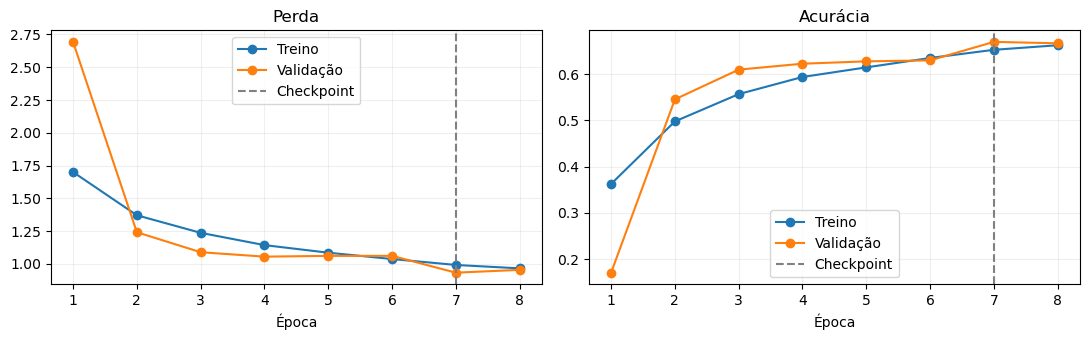

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, metric, title in zip(axes, ['loss', 'accuracy'], ['Perda', 'Acurácia']):
    ax.plot(history.index, history[metric], marker='o', label='Treino')
    ax.plot(history.index, history[f'val_{metric}'], marker='o', label='Validação')
    ax.axvline(best_epoch, color='gray', ls='--', label='Checkpoint')
    ax.set(xlabel='Época', title=title, xticks=history.index)
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

In [3]:
best = history.loc[best_epoch]
print(f'Na época {best_epoch}, perda de validação = {best.val_loss:.4f}.')
print(f'Acurácia por época · treino {best.accuracy:.2%} · validação {best.val_accuracy:.2%}.')
print(f'Maior acurácia de validação · {history.val_accuracy.max():.2%} na época {history.val_accuracy.idxmax()}.')
print(f'Perda de validação · primeira época {history.val_loss.iloc[0]:.4f} · última época {history.val_loss.iloc[-1]:.4f}.')

Na época 7, perda de validação = 0.9330.
Acurácia por época · treino 65.25% · validação 66.97%.
Maior acurácia de validação · 66.97% na época 7.
Perda de validação · primeira época 2.6936 · última época 0.9545.


## Diagnóstico da rodada

A perda de validação caiu de 2,694 na primeira época para 0,933 na sétima. Na oitava, a perda de treino continuou caindo, enquanto a de validação subiu para 0,955. A diferença de acurácia em inferência foi de 1,28 ponto percentual no checkpoint selecionado. Com oito épocas e uma semente, a última oscilação é um sinal para acompanhar em uma rodada mais longa.

O próximo experimento pode ampliar apenas o orçamento de épocas, com a mesma divisão e os callbacks atuais. Compare a menor perda de validação, o F1 macro e o recall de gato.